# 03 Model: which customers are worth calling first? (supporting part)

SQL and Power BI are the core of this project. This notebook is the small supporting piece: one logistic regression that ranks customers by how likely they are to subscribe, so the call list can be ordered.

Rules I set before starting:
- `duration` is excluded. It is only known after the call ends, so it cannot be used to decide who to call.
- Nominal columns are one-hot encoded (no fake alphabetical order from label encoding).
- Time-based split, because the rows are in date order.
- Accuracy is not the headline metric. Always predicting "no" is already very accurate; I report AUC, recall, precision and lift instead.
- Every number below is computed in code.

In [1]:
import sys

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score

sys.path.append(".")
from bm_analysis import gains_table, load_clean

df = load_clean()          # validated: fails loudly if bank_clean.csv was damaged (for example saved by Excel)
print(f"{len(df):,} rows, yes rate {df['y_flag'].mean():.1%}")

41,176 rows, yes rate 11.3%


## 1. Which columns go in, and why

| Column(s) | Decision | Why |
|---|---|---|
| `duration` | dropped | known only after the call (leakage) |
| `campaign` | kept | number of contacts in this campaign; a plain operational variable |
| `pdays` | dropped | 999 means "never contacted" and disagrees with `previous` (see notebook 01); `previously_contacted` carries the same information |
| `month`, `day_of_week`, `year`, `campaign_period` | dropped | calendar time; I do not want the model to just learn "2010 is good" |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | dropped from the main model | macro indicators move together with the calendar year; tested as a sensitivity check in section 5 |
| `job, marital, education, default, housing, loan, contact, poutcome` | one-hot | nominal; `unknown` kept as its own level |
| `previously_contacted` | not used separately | it is the same information as `poutcome` (not `nonexistent`), so it would be duplicated |
| `age`, `campaign` | standardised | so odds ratios are "per 1 standard deviation" and comparable |

In [2]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
num_cols = ["age", "campaign"]

# time-based split: rows are in date order, so first 80% = train, last 20% = test
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]

X = pd.get_dummies(df[cat_cols + num_cols], columns=cat_cols).astype(float)
# reference level for each nominal column = its most common level, so odds ratios read as "vs the typical customer"
reference = {c: df[c].value_counts().idxmax() for c in cat_cols}
X = X.drop(columns=[f"{c}_{lvl}" for c, lvl in reference.items()])
print("Reference levels:", reference)

# scale only age and campaign, with training-set mean/std (no peeking at test)
scale_cols = ["age", "campaign"]
mu, sd = X[scale_cols].iloc[:cut].mean(), X[scale_cols].iloc[:cut].std()
X[scale_cols] = (X[scale_cols] - mu) / sd

X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = train["y_flag"], test["y_flag"]

split_table = pd.DataFrame({
    "rows": [len(train), len(test)],
    "yes_rate": [y_train.mean(), y_test.mean()],
    "years": [", ".join(f"{y} ({n:,})" for y, n in train["year"].value_counts().sort_index().items()),
              ", ".join(f"{y} ({n:,})" for y, n in test["year"].value_counts().sort_index().items())],
}, index=["train", "test"])
split_table["yes_rate"] = split_table["yes_rate"].map("{:.1%}".format)
split_table

Reference levels: {'job': 'admin.', 'marital': 'married', 'education': 'university.degree', 'default': 'no', 'housing': 'yes', 'loan': 'no', 'contact': 'cellular', 'poutcome': 'nonexistent'}


,rows,yes_rate,years
train,32940,6.4%,"2008 (27,682), 2009 (5,258)"
test,8236,30.8%,"2009 (6,178), 2010 (2,058)"


**Finding (read this before any metric).** The split is not like-for-like: the training period is mostly 2008, when the yes rate was low, and the test period is 2009-2010, when it was much higher (the table above shows both). So the model is being asked to rank customers in a different environment from the one it learned in. That is a realistic test of "does the ranking still work later", but absolute probabilities will be too low on the test set. I therefore judge the model on how well it ranks (AUC, lift), not on calibrated probabilities or accuracy.

In [3]:
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]

baseline_acc = 1 - y_test.mean()          # always predicting "no"
auc = roc_auc_score(y_test, p_test)
print(f"Always-'no' accuracy on test set: {baseline_acc:.1%}")
print(f"ROC-AUC on test set:              {auc:.3f}   (0.5 = random ranking)")

# Within each test year, so the year mix cannot create the result
for yr, g in test.assign(p=p_test).groupby("year"):
    print(f"  ROC-AUC inside {yr} only: {roc_auc_score(g['y_flag'], g['p']):.3f}  ({len(g):,} customers)")

Always-'no' accuracy on test set: 69.2%
ROC-AUC on test set:              0.693   (0.5 = random ranking)
  ROC-AUC inside 2009 only: 0.661  (6,178 customers)
  ROC-AUC inside 2010 only: 0.704  (2,058 customers)


## 2. Using the ranking: call the top 20% of customers

A bank does not need a yes/no cut-off at 0.5 (that gives very few "yes" predictions when yes is rare). It needs an ordered call list. So I ask: if I call only the top 20% of customers by score, what share of all subscribers do I reach, and how much better is that than calling 20% at random?

In [4]:
gt = gains_table(y_test, p_test)
show = gt.copy()
show["share_of_list"] = show["share_of_list"].map("{:.0%}".format)
show["share_of_all_subscribers"] = show["share_of_all_subscribers"].map("{:.1%}".format)
show["lift_vs_random"] = show["lift_vs_random"].map("{:.2f}x".format)
print(show.to_string(index=False))

row = gt[gt["share_of_list"] == 0.20].iloc[0]
print(f"\nCalling the top 20% ({int(row['customers_called']):,} of {len(y_test):,} customers) reaches "
      f"{row['share_of_all_subscribers']:.1%} of all subscribers in the test period, "
      f"a lift of {row['lift_vs_random']:.2f}x over random calling.")

 customers_called share_of_list  subscribers_reached share_of_all_subscribers lift_vs_random
              411            5%                  291                    11.5%          2.29x
              823           10%                  580                    22.8%          2.28x
             1647           20%                  992                    39.1%          1.95x
             2470           30%                 1264                    49.8%          1.66x
             4118           50%                 1715                    67.5%          1.35x

Calling the top 20% (1,647 of 8,236 customers) reaches 39.1% of all subscribers in the test period, a lift of 1.95x over random calling.


At threshold 0.5: predicted yes = 238, recall = 7.0%, precision = 74.8%, accuracy = 70.6% (always-'no' = 69.2%)


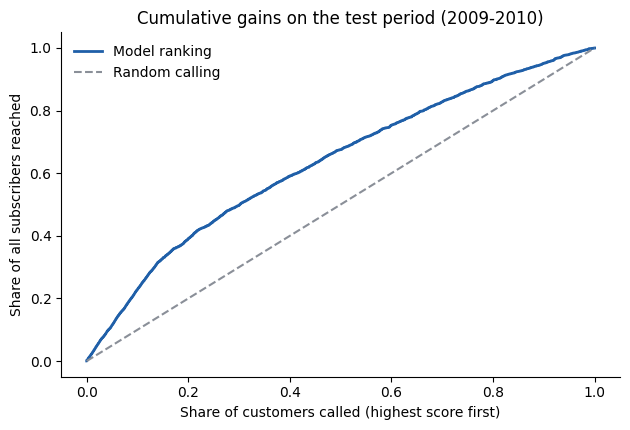

In [5]:
# Same table for the 0.5 threshold, to show why I do not use it
pred = (p_test >= 0.5).astype(int)
print(f"At threshold 0.5: predicted yes = {pred.sum():,}, "
      f"recall = {recall_score(y_test, pred, zero_division=0):.1%}, "
      f"precision = {precision_score(y_test, pred, zero_division=0):.1%}, "
      f"accuracy = {accuracy_score(y_test, pred):.1%} (always-'no' = {baseline_acc:.1%})")

# Gains chart
fig, ax = plt.subplots(figsize=(6.4, 4.4))
order = np.argsort(-p_test)
cum = np.cumsum(y_test.values[order]) / y_test.sum()
x = np.arange(1, len(cum) + 1) / len(cum)
ax.plot(x, cum, color="#1f5fa8", lw=2, label="Model ranking")
ax.plot([0, 1], [0, 1], color="#8a8f98", ls="--", label="Random calling")
ax.set_xlabel("Share of customers called (highest score first)")
ax.set_ylabel("Share of all subscribers reached")
ax.set_title("Cumulative gains on the test period (2009-2010)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../Data/visualizations/03_gains.png", dpi=150)
plt.show()

## 3. What the model says, in business language

Coefficients are converted to odds ratios (exp of the coefficient). An odds ratio above 1 means a higher chance of subscribing than the reference group, below 1 means lower, holding the other columns fixed. For `age` and `campaign` the ratio is per 1 standard deviation. These are associations in one bank's data, not causes.

In [6]:
coef = pd.Series(model.coef_[0], index=X.columns)
odds = pd.DataFrame({"odds_ratio": np.exp(coef)})
# group sizes in the training set, so a big ratio from a tiny group is visible
sizes = {c: int(X_train[c].sum()) for c in X.columns if c not in ["age", "campaign"]}
odds["train_customers"] = pd.Series(sizes)
odds = odds.sort_values("odds_ratio", ascending=False)
print("Highest:"); print(odds.head(6).round(2).to_string())
print("\nLowest:");  print(odds.tail(6).round(2).to_string())

Highest:
                      odds_ratio  train_customers
poutcome_success            6.48            168.0
job_student                 2.65            347.0
job_retired                 2.12            989.0
marital_single              1.21           8384.0
job_self-employed           1.11           1156.0
education_illiterate        1.07             14.0

Lowest:
                    odds_ratio  train_customers
campaign                  0.86              NaN
education_basic.4y        0.83           3432.0
job_housemaid             0.76            880.0
poutcome_failure          0.72           2107.0
default_unknown           0.67           8016.0
contact_telephone         0.53          14049.0


In [7]:
def orr(name): return odds.loc[name, "odds_ratio"]

print(f"- Previous campaign succeeded (vs never contacted before): {orr('poutcome_success'):.2f}")
print(f"- Previous campaign failed (vs never contacted before): {orr('poutcome_failure'):.2f}")
print(f"- Cellular vs landline (telephone): {orr('contact_telephone') ** -1:.2f}")
print(f"- One more standard deviation of contacts in this campaign: {orr('campaign'):.2f}")
print(f"- One standard deviation older: {orr('age'):.2f}")

- Previous campaign succeeded (vs never contacted before): 6.48
- Previous campaign failed (vs never contacted before): 0.72
- Cellular vs landline (telephone): 1.88
- One more standard deviation of contacts in this campaign: 0.86
- One standard deviation older: 1.00


## 4. What I tried and changed

Short log, because it explains the choices above.

In [8]:
# 4a. Does a random split give a different (more flattering) answer than the time split?
from sklearn.model_selection import train_test_split
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, df["y_flag"], test_size=0.2, random_state=42, stratify=df["y_flag"])
m_r = LogisticRegression(max_iter=2000).fit(Xr_tr, yr_tr)
auc_random = roc_auc_score(yr_te, m_r.predict_proba(Xr_te)[:, 1])
print(f"AUC with random split: {auc_random:.3f}   vs time-based split: {auc:.3f}")

AUC with random split: 0.726   vs time-based split: 0.693


In [9]:
# 4b. Add the macro indicator euribor3m? It tracks the calendar, so I only test it, I do not adopt it.
extra = "euribor3m"
Xe = X.copy()
e_mu, e_sd = df[extra].iloc[:cut].mean(), df[extra].iloc[:cut].std()
Xe[extra] = (df[extra] - e_mu) / e_sd
m_e = LogisticRegression(max_iter=2000).fit(Xe.iloc[:cut], y_train)
auc_e = roc_auc_score(y_test, m_e.predict_proba(Xe.iloc[cut:])[:, 1])
print(f"AUC with euribor3m added: {auc_e:.3f}   vs main model: {auc:.3f}")

AUC with euribor3m added: 0.703   vs main model: 0.693


In [10]:
# 4c. `campaign` is strongly right-skewed (see the skew printed below). Rule of thumb from the EDA checklist:
# when |skew| > 2, test a transform before trusting a linear model. I test it and report it; the main model is unchanged.
from scipy.stats import skew

print(f"skew of campaign: {skew(df['campaign']):.2f} (max {df['campaign'].max()})")

results = {}
for label, transform in {"raw (main model)": lambda s: s, "log1p": np.log1p, "capped at 10": lambda s: s.clip(upper=10)}.items():
    Xt = X.copy()
    t = transform(df["campaign"]).astype(float)
    t_mu, t_sd = t.iloc[:cut].mean(), t.iloc[:cut].std()          # training-set statistics only
    Xt["campaign"] = (t - t_mu) / t_sd
    m = LogisticRegression(max_iter=2000, random_state=42).fit(Xt.iloc[:cut], y_train)
    p = m.predict_proba(Xt.iloc[cut:])[:, 1]
    top20 = gains_table(y_test, p).query("share_of_list == 0.2").iloc[0]
    results[label] = {"test_auc": roc_auc_score(y_test, p),
                      "share_of_subscribers_in_top20pct": top20["share_of_all_subscribers"],
                      "lift_top20pct": top20["lift_vs_random"]}
pd.DataFrame(results).T.round(3)

skew of campaign: 4.76 (max 56)


,test_auc,share_of_subscribers_in_top20pct,lift_top20pct
raw (main model),0.693,0.391,1.954
log1p,0.693,0.390,1.952
capped at 10,0.693,0.390,1.952


**Finding (4c).** Transforming `campaign` (log, or capping at 10 contacts) leaves the ranking unchanged: test AUC 0.693 and top-20% lift of about 1.95x in all three versions. The skew does not matter for a ranking model of this size, so the main model keeps the raw count, which is the easiest to explain. The check was done because the EDA checklist asks for it when |skew| > 2.

## 5. Limits (read before quoting any number)

- **Different period in test vs train.** Training is mostly 2008, test is 2009-2010. The ranking is evaluated across that shift; probabilities are not calibrated to the test period.
- **Modest model.** One logistic regression on client and contact-history columns only. It is a ranking aid, not a decision engine.
- **Associations, not causes**, from one Portuguese bank in 2008-2010. Not evidence about the Thai market.
- **No cost data.** I do not turn the lift into baht. If I did, the cost per call would be a labelled assumption.
- **The Power BI report does not depend on this notebook.** It is supporting evidence for the SQL and dashboard findings.